# Next-Season PPA Model — XGBoost (Regression)

 **PPA in the NEXT season** from their **current-season** stats.

In [1]:
!pip -q install xgboost
!pip -q install -U shap

In [2]:
import pandas as pd
import numpy as np
from plotnine import *
import xgboost as xgb
from sklearn.model_selection import ParameterGrid, GroupKFold, GroupShuffleSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from tqdm import tqdm
import matplotlib.pyplot as plt
import shap

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

## Configuration

In [3]:
TRAIN_PATH = "master_train.csv"
TEST_PATH  = "master_test.csv"

ID_COL, SEASON_COL = "athlete_id", "season"
PPA_COL   = "avg_PPA_all"
USAGE_COL = "usg_overall"
POS_COL   = "position.x"

POSITION_FILTER = "WR"

MIN_USAGE_CURRENT = 0.05
MIN_USAGE_NEXT    = 0.05


FEATURE_PREFIXES = ("avg_PPA_", "total_PPA_", "usg_", "passing_", "rushing_", "receiving_",
                    "fumbles_", "defensive_", "interceptions_", "kicking_", "kick_returns_",
                    "punting_", "punt_returns_")

## Load data

In [4]:
train_raw = pd.read_csv(TRAIN_PATH, low_memory=False)
test_raw  = pd.read_csv(TEST_PATH,  low_memory=False)
print("train:", train_raw.shape, "| seasons:", sorted(int(s) for s in train_raw[SEASON_COL].unique()))
print("test: ", test_raw.shape,  "| seasons:", sorted(int(s) for s in test_raw[SEASON_COL].unique()))
assert list(train_raw.columns) == list(test_raw.columns), "train/test columns differ"

train: (54387, 143) | seasons: [2021, 2022, 2023, 2024]
test:  (15098, 143) | seasons: [2025]


## Clean: one row per player-season

In [5]:
def clean_player_seasons(df):
    d = df[df[PPA_COL].notna() & df[USAGE_COL].notna()].copy()
    d["_team_match"] = (d["team_stats"] == d["team_ppa"]).astype(int)
    d["_n_nonnull"]  = d.notna().sum(axis=1)
    d = (d.sort_values(["_team_match", "_n_nonnull"], ascending=False)
           .drop_duplicates([ID_COL, SEASON_COL])
           .drop(columns=["_team_match", "_n_nonnull"]))
    d["is_transfer"]   = d["origin"].notna().astype(int)
    d["portal_rating"] = d["rating.y"]
    d["portal_stars"]  = d["stars.y"]
    return d.reset_index(drop=True)

train_clean = clean_player_seasons(train_raw)
test_clean  = clean_player_seasons(test_raw)
if POSITION_FILTER is not None:
    train_clean = train_clean[train_clean[POS_COL] == POSITION_FILTER].reset_index(drop=True)
    test_clean  = test_clean[test_clean[POS_COL] == POSITION_FILTER].reset_index(drop=True)

print("Position(s) in train_clean:", train_clean[POS_COL].value_counts().to_dict())
print("Position(s) in test_clean: ", test_clean[POS_COL].value_counts().to_dict())
print("player-seasons with PPA -> train:", len(train_clean), "| test:", len(test_clean))
train_clean.groupby(SEASON_COL).size()

Position(s) in train_clean: {'WR': 7188}
Position(s) in test_clean:  {'WR': 2310}
player-seasons with PPA -> train: 7188 | test: 2310


,0
season,
2021,1373
2022,2087
2023,1917
2024,1811


count    7188.000000
mean        0.048834
std         0.035052
min         0.010000
25%         0.025000
50%         0.041000
75%         0.064000
max         0.589000
Name: usg_overall, dtype: float64
usage >= 0.03: 67.2% of player-seasons
usage >= 0.05: 38.7% of player-seasons
usage >= 0.10: 7.4% of player-seasons
usage >= 0.15: 1.2% of player-seasons


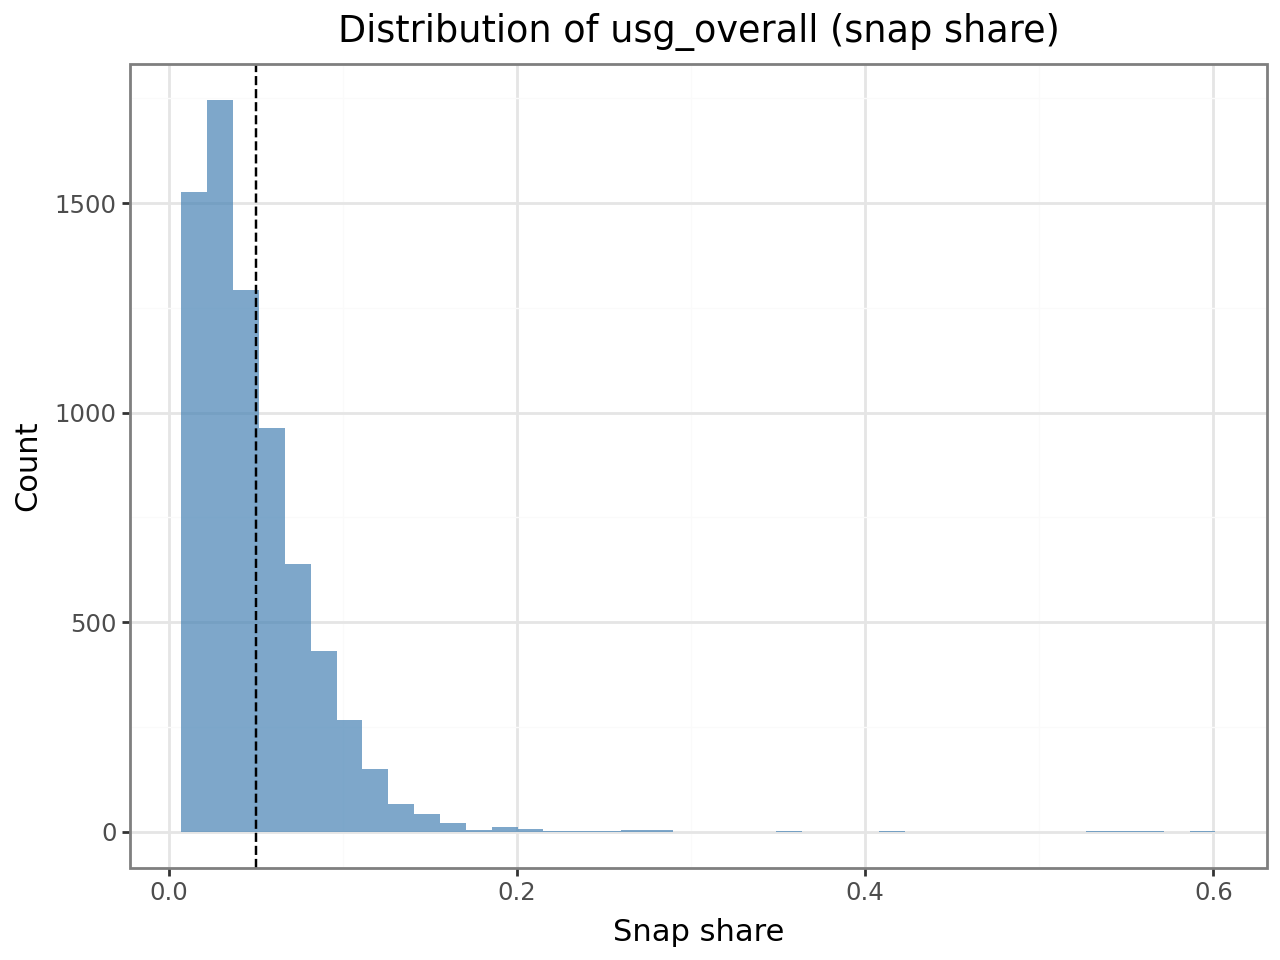

In [6]:
print(train_clean[USAGE_COL].describe())
for thr in [0.03, 0.05, 0.10, 0.15]:
    print(f"usage >= {thr:.2f}: {(train_clean[USAGE_COL] >= thr).mean():.1%} of player-seasons")

(
    ggplot(train_clean, aes(x=USAGE_COL))
    + geom_histogram(bins=40, fill="steelblue", alpha=0.7)
    + geom_vline(xintercept=MIN_USAGE_CURRENT, linetype="dashed")
    + theme_bw()
    + labs(title="Distribution of usg_overall (snap share)", x="Snap share", y="Count")
)

In [7]:
feature_num_cols = [c for c in train_clean.columns
                    if c.startswith(FEATURE_PREFIXES)] + ["is_transfer", "portal_rating", "portal_stars"]
POSITIONS = sorted(train_clean[POS_COL].dropna().unique())
print(len(feature_num_cols), "numeric features;", "positions:", POSITIONS)

def build_next_season_pairs(cur, nxt):
    """Join each player's season-t row (features) to their season-(t+1) PPA (target)."""
    cur = cur[cur[USAGE_COL] >= MIN_USAGE_CURRENT].copy()
    tgt = nxt.loc[nxt[USAGE_COL] >= MIN_USAGE_NEXT,
                  [ID_COL, SEASON_COL, PPA_COL, USAGE_COL, "team"]].copy()
    tgt[SEASON_COL] = tgt[SEASON_COL] - 1            # line season t+1 up with season t
    tgt = tgt.rename(columns={PPA_COL: "next_ppa", USAGE_COL: "next_usage", "team": "next_team"})
    return cur.merge(tgt, on=[ID_COL, SEASON_COL], how="inner")

def make_xy(pairs):
    X = pairs[feature_num_cols].apply(pd.to_numeric, errors="coerce").copy()
    for p in POSITIONS:
        X[f"pos_{p}"] = (pairs[POS_COL] == p).astype(int)
    return X, pairs["next_ppa"]

train_pairs = build_next_season_pairs(train_clean, train_clean)

test_season = int(test_clean[SEASON_COL].min())
test_pairs  = build_next_season_pairs(train_clean[train_clean[SEASON_COL] == test_season - 1], test_clean)

X_train_full, y_train_full = make_xy(train_pairs)
X_test, y_test             = make_xy(test_pairs)
groups_full = train_pairs[ID_COL].values

print(f"Train pairs: {len(train_pairs)}  (by feature season: {train_pairs[SEASON_COL].value_counts().sort_index().to_dict()})")
print(f"Test pairs:  {len(test_pairs)}  ({test_season - 1} -> {test_season})")
print("X columns:", X_train_full.shape[1])
train_pairs[[ID_COL, "name", SEASON_COL, "team", PPA_COL, USAGE_COL, "next_team", "next_ppa"]].head()

81 numeric features; positions: ['WR']
Train pairs: 913  (by feature season: {2021: 280, 2022: 345, 2023: 288})
Test pairs:  282  (2024 -> 2025)
X columns: 82


,athlete_id,name,season,team,avg_PPA_all,usg_overall,next_team,next_ppa
0,4595348,Malik Nabers,2022,LSU,1.075,0.087,LSU,0.961
1,4683062,Xavier Worthy,2021,Texas,0.917,0.102,Texas,0.343
2,4683062,Xavier Worthy,2022,Texas,0.343,0.126,Texas,0.566
3,4432708,Marvin Harrison Jr.,2022,Ohio State,0.914,0.131,Ohio State,1.258
4,4595348,Malik Nabers,2021,LSU,0.963,0.061,LSU,1.075


## Target distribution

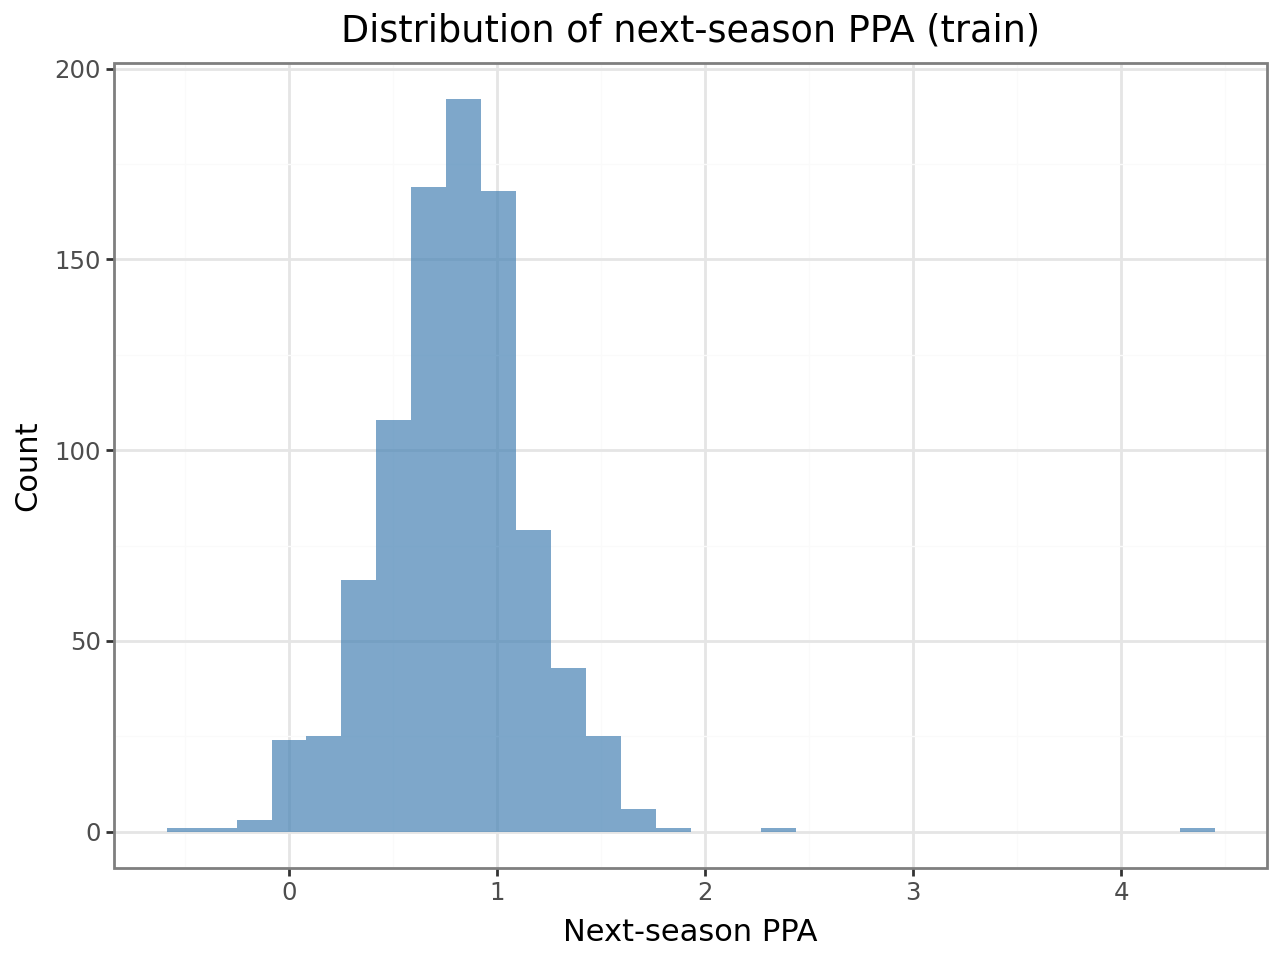

In [8]:
(
    ggplot(train_pairs, aes(x="next_ppa"))
    + geom_histogram(bins=30, fill="steelblue", alpha=0.7)
    + theme_bw()
    + labs(title="Distribution of next-season PPA (train)", x="Next-season PPA", y="Count")
)

In [9]:
mean_pred = np.full(len(y_test), y_train_full.mean())
persist_pred = X_test[PPA_COL].values

print(f"Test RMSE | predict train mean : {rmse(y_test, mean_pred):.4f}")
print(f"Test RMSE | persistence (PPA_t) : {rmse(y_test, persist_pred):.4f}")
print(f"Test corr(PPA_t, PPA_t+1)       : {np.corrcoef(X_test[PPA_COL], y_test)[0,1]:.3f}")

Test RMSE | predict train mean : 0.4213
Test RMSE | persistence (PPA_t) : 0.6475
Test corr(PPA_t, PPA_t+1)       : 0.164


In [10]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, val_idx = next(gss.split(X_train_full, y_train_full, groups_full))

X_train, y_train = X_train_full.iloc[tr_idx], y_train_full.iloc[tr_idx]
X_val,   y_val   = X_train_full.iloc[val_idx], y_train_full.iloc[val_idx]
groups_train = groups_full[tr_idx]
print(X_train.shape, X_val.shape)

dtrain = xgb.DMatrix(data=X_train, label=y_train)
dval   = xgb.DMatrix(data=X_val,   label=y_val)

folds = list(GroupKFold(n_splits=5).split(X_train, y_train, groups_train))

(727, 82) (186, 82)


## Baseline XGBoost model

In [11]:
params = {
    "objective": "reg:squarederror",
    "eval_metric": ["rmse", "mae"],
    "tree_method": "hist",
    "seed": 42,
}
booster = xgb.train(params, dtrain, num_boost_round=300,
                    evals=[(dtrain, "train"), (dval, "val")], verbose_eval=20)

val_pred_raw = booster.predict(dval)
print(f"Validation RMSE | mean baseline: {rmse(y_val, np.full(len(y_val), y_train.mean())):.4f}")
print(f"Validation RMSE | baseline XGB : {rmse(y_val, val_pred_raw):.4f}")

[0]	train-rmse:0.32688	train-mae:0.24120	val-rmse:0.34497	val-mae:0.26594
[20]	train-rmse:0.11957	train-mae:0.08797	val-rmse:0.36380	val-mae:0.28701
[40]	train-rmse:0.04689	train-mae:0.03282	val-rmse:0.36969	val-mae:0.29269
[60]	train-rmse:0.01682	train-mae:0.01133	val-rmse:0.37095	val-mae:0.29341
[80]	train-rmse:0.00713	train-mae:0.00476	val-rmse:0.37160	val-mae:0.29391
[100]	train-rmse:0.00303	train-mae:0.00201	val-rmse:0.37212	val-mae:0.29427
[120]	train-rmse:0.00133	train-mae:0.00089	val-rmse:0.37224	val-mae:0.29444
[140]	train-rmse:0.00072	train-mae:0.00049	val-rmse:0.37224	val-mae:0.29447
[160]	train-rmse:0.00072	train-mae:0.00049	val-rmse:0.37224	val-mae:0.29447
[180]	train-rmse:0.00072	train-mae:0.00049	val-rmse:0.37224	val-mae:0.29447
[200]	train-rmse:0.00072	train-mae:0.00049	val-rmse:0.37224	val-mae:0.29447
[220]	train-rmse:0.00072	train-mae:0.00049	val-rmse:0.37224	val-mae:0.29447
[240]	train-rmse:0.00072	train-mae:0.00049	val-rmse:0.37224	val-mae:0.29447
[260]	train-rmse:0

## Tuning: baseline CV

In [12]:
cv_params = {
    "objective": "reg:squarederror",
    "eta": 0.1,
    "eval_metric": "rmse",
    "tree_method": "hist",
    "seed": 111111,
}
cv_res = xgb.cv(params=cv_params, dtrain=dtrain, num_boost_round=400,
                folds=folds, verbose_eval=20, seed=111111)
cv_res.head()

[0]	train-rmse:0.35307+0.00839	test-rmse:0.36288+0.03130
[20]	train-rmse:0.20559+0.01866	test-rmse:0.36300+0.04238
[40]	train-rmse:0.15205+0.02304	test-rmse:0.37369+0.05167
[60]	train-rmse:0.11019+0.01520	test-rmse:0.37846+0.05340
[80]	train-rmse:0.08169+0.01113	test-rmse:0.38042+0.05321
[100]	train-rmse:0.05872+0.00879	test-rmse:0.38168+0.05326
[120]	train-rmse:0.04394+0.00581	test-rmse:0.38283+0.05290
[140]	train-rmse:0.03282+0.00377	test-rmse:0.38361+0.05231
[160]	train-rmse:0.02373+0.00238	test-rmse:0.38400+0.05237
[180]	train-rmse:0.01791+0.00175	test-rmse:0.38434+0.05237
[200]	train-rmse:0.01340+0.00102	test-rmse:0.38448+0.05232
[220]	train-rmse:0.01006+0.00078	test-rmse:0.38464+0.05244
[240]	train-rmse:0.00766+0.00061	test-rmse:0.38473+0.05255
[260]	train-rmse:0.00565+0.00064	test-rmse:0.38483+0.05260
[280]	train-rmse:0.00420+0.00049	test-rmse:0.38485+0.05262
[300]	train-rmse:0.00308+0.00047	test-rmse:0.38490+0.05262
[320]	train-rmse:0.00227+0.00029	test-rmse:0.38490+0.05262
[34

,train-rmse-mean,train-rmse-std,test-rmse-mean,test-rmse-std
0,0.353070,0.008394,0.362880,0.031298
1,0.340164,0.008490,0.360358,0.031965
2,0.328124,0.008969,0.359459,0.031797
3,0.317205,0.009630,0.357798,0.031851
4,0.306769,0.010268,0.357038,0.032035


In [13]:
best_idx = cv_res['test-rmse-mean'].idxmin()
best_iter = int(best_idx) + 1
best_rmse = float(cv_res.loc[best_idx, 'test-rmse-mean'])
print(f"Best iteration (by min test RMSE): {best_iter}")
print(f"Min test RMSE at best iter: {best_rmse:.4f}")

Best iteration (by min test RMSE): 11
Min test RMSE at best iter: 0.3561


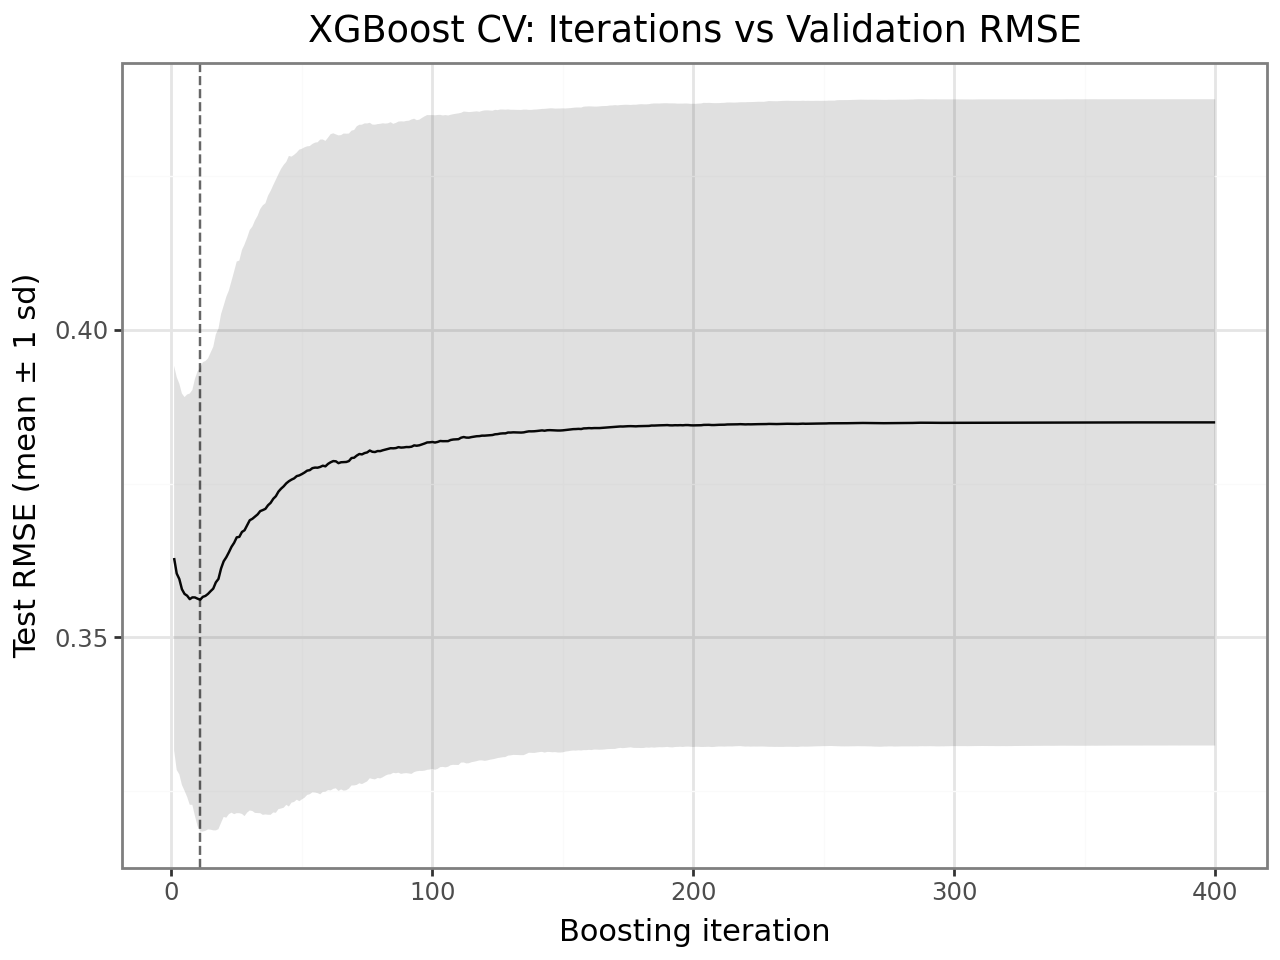

In [14]:
df_plot = cv_res.reset_index().rename(columns={"index": "iter"})
df_plot["iter"] = df_plot["iter"] + 1
df_plot = df_plot.rename(columns=lambda c: c.replace("-", "_"))
df_plot["lower"] = df_plot["test_rmse_mean"] - df_plot["test_rmse_std"]
df_plot["upper"] = df_plot["test_rmse_mean"] + df_plot["test_rmse_std"]

(
    ggplot(df_plot, aes(x="iter", y="test_rmse_mean"))
    + geom_line()
    + geom_ribbon(aes(ymin="lower", ymax="upper"), alpha=0.15)
    + geom_vline(xintercept=best_iter, linetype="dashed", alpha=0.6)
    + theme_bw()
    + labs(title="XGBoost CV: Iterations vs Validation RMSE",
           x="Boosting iteration", y="Test RMSE (mean ± 1 sd)")
)

## Tuning stage 1: max_depth / min_child_weight

With a small sample, shallow trees and a higher `min_child_weight` will probably win — the grid confirms it.

In [15]:
grid = {"max_depth": [2, 3, 5, 7], "min_child_weight": [1, 3, 5, 7]}
param_grid = list(ParameterGrid(grid))

base_params = {
    "objective": "reg:squarederror",
    "eta": 0.10,
    "eval_metric": "rmse",
    "tree_method": "hist",
    "seed": 111111,
}

def run_one_cv(md_, mcw):
    params = base_params.copy()
    params.update({"max_depth": int(md_), "min_child_weight": int(mcw)})
    cv = xgb.cv(params=params, dtrain=dtrain, num_boost_round=500, folds=folds,
                early_stopping_rounds=20, verbose_eval=False, seed=111111)
    best_round = len(cv)
    return {"max_depth": md_, "min_child_weight": mcw, "best_round": best_round,
            "test_rmse": float(cv.iloc[best_round - 1]["test-rmse-mean"])}

results = [run_one_cv(p["max_depth"], p["min_child_weight"]) for p in tqdm(param_grid)]
cv_results_df = pd.DataFrame(results).sort_values("test_rmse").reset_index(drop=True)
display(cv_results_df)

best_pair = cv_results_df.iloc[0].to_dict()
tuned_max_depth = int(best_pair["max_depth"])
tuned_min_child = int(best_pair["min_child_weight"])
print("Best:", best_pair)

100%|██████████| 16/16 [00:13<00:00,  1.19it/s]


,max_depth,min_child_weight,best_round,test_rmse
0,2,3,41,0.349574
1,3,3,22,0.349844
2,2,7,22,0.350996
3,5,3,15,0.351049
4,7,3,15,0.351508
5,5,7,8,0.352303
6,3,7,11,0.352480
7,5,1,8,0.352924
8,2,5,31,0.353060
9,3,1,9,0.353878


Best: {'max_depth': 2.0, 'min_child_weight': 3.0, 'best_round': 41.0, 'test_rmse': 0.3495736408762193}


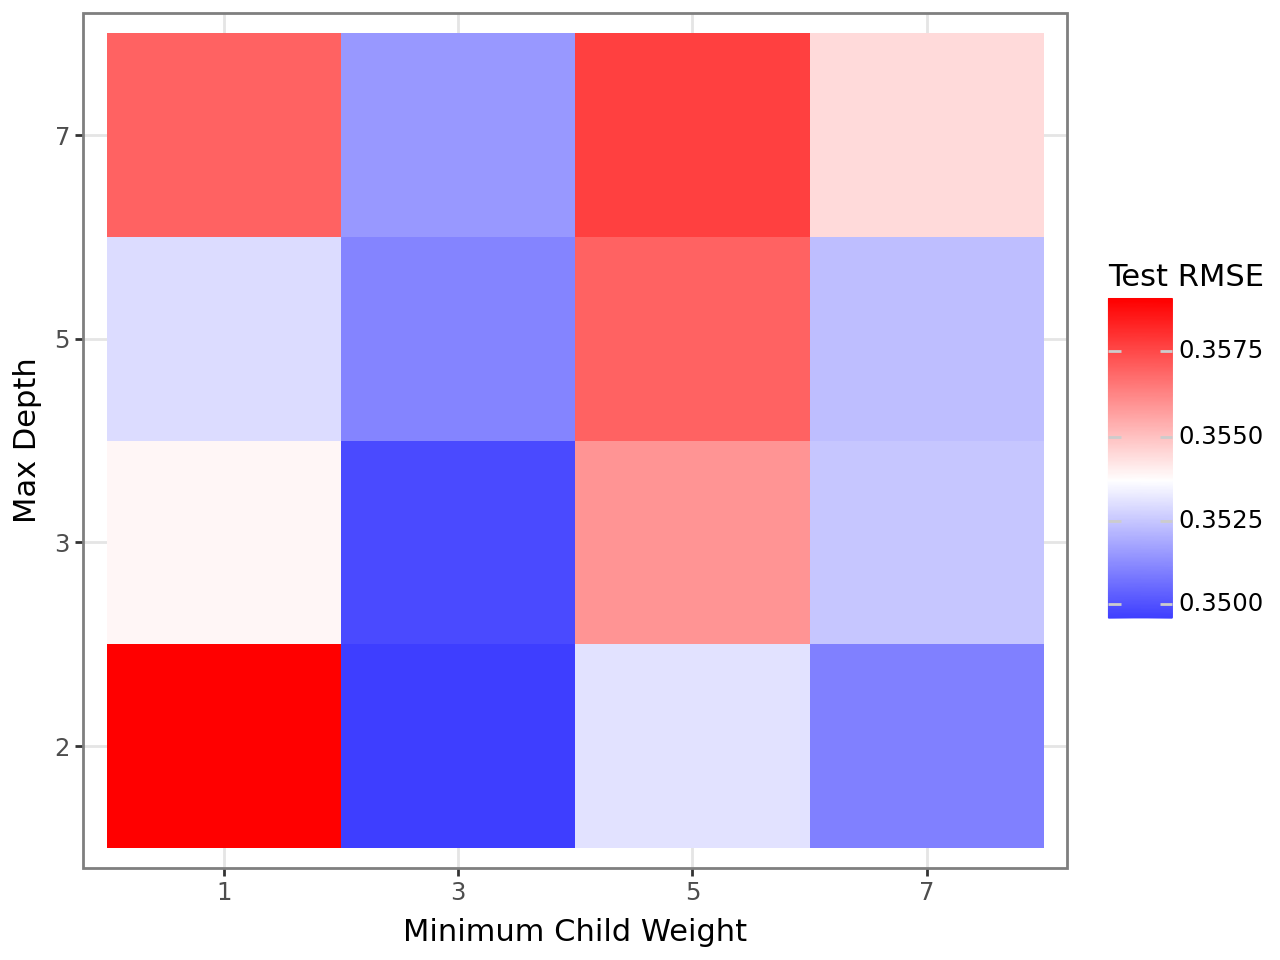

In [16]:
res_db = cv_results_df.copy()
res_db["max_depth"] = res_db["max_depth"].astype("category")
res_db["min_child_weight"] = res_db["min_child_weight"].astype("category")

(
    ggplot(res_db, aes(y="max_depth", x="min_child_weight", fill="test_rmse"))
    + geom_tile()
    + theme_bw()
    + scale_fill_gradient2(low="blue", mid="white", high="red", midpoint=res_db["test_rmse"].mean())
    + labs(x="Minimum Child Weight", y="Max Depth", fill="Test RMSE")
)

## Tuning stage 2: gamma

In [17]:
gamma_vals = [0.0, 0.5, 1.0, 5.0, 10.0]
base_params.update({"max_depth": tuned_max_depth, "min_child_weight": tuned_min_child})

rows = []
for g in tqdm(gamma_vals):
    params = base_params.copy()
    params["gamma"] = float(g)
    cv = xgb.cv(params=params, dtrain=dtrain, num_boost_round=300, folds=folds,
                early_stopping_rounds=20, verbose_eval=False, seed=111111)
    best_round = len(cv)
    rows.append({"gamma": g, "best_round": best_round,
                 "test_rmse": float(cv.iloc[best_round - 1]["test-rmse-mean"])})

gamma_results = pd.DataFrame(rows).sort_values("test_rmse").reset_index(drop=True)
display(gamma_results)
tuned_gamma = float(gamma_results.iloc[0]["gamma"])
print(f"Selected gamma: {tuned_gamma}")

100%|██████████| 5/5 [00:02<00:00,  2.19it/s]


,gamma,best_round,test_rmse
0,0.5,41,0.349019
1,0.0,41,0.349574
2,1.0,92,0.351858
3,5.0,3,0.362149
4,10.0,1,0.366667


Selected gamma: 0.5


In [18]:
grid = {"subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.6, 0.8, 1.0]}
param_grid = list(ParameterGrid(grid))
base_params.update({"gamma": tuned_gamma})

def run_one_cv_sc(subsample, colsample_bytree):
    params = base_params.copy()
    params.update({"subsample": float(subsample), "colsample_bytree": float(colsample_bytree)})
    cv = xgb.cv(params=params, dtrain=dtrain, num_boost_round=300, folds=folds,
                early_stopping_rounds=20, verbose_eval=False, seed=111111)
    best_round = len(cv)
    return {"subsample": subsample, "colsample_bytree": colsample_bytree,
            "best_round": best_round, "test_rmse": float(cv.iloc[best_round - 1]["test-rmse-mean"])}

sc_results = pd.DataFrame([run_one_cv_sc(p["subsample"], p["colsample_bytree"])
                           for p in tqdm(param_grid)]).sort_values("test_rmse").reset_index(drop=True)
display(sc_results)
best_sc = sc_results.iloc[0].to_dict()
tuned_subsample = float(best_sc["subsample"])
tuned_colsample = float(best_sc["colsample_bytree"])
print("Best:", best_sc)

100%|██████████| 9/9 [00:04<00:00,  2.11it/s]


,subsample,colsample_bytree,best_round,test_rmse
0,1.0,0.8,42,0.348172
1,1.0,1.0,41,0.349019
2,0.6,0.6,14,0.350105
3,1.0,0.6,38,0.350246
4,0.8,0.8,12,0.350419
5,0.8,1.0,22,0.350804
6,0.6,0.8,19,0.351215
7,0.8,0.6,12,0.352364
8,0.6,1.0,27,0.353677


Best: {'subsample': 1.0, 'colsample_bytree': 0.8, 'best_round': 42.0, 'test_rmse': 0.3481720830301073}


In [19]:
etas = [0.3, 0.1, 0.05, 0.01]
base_params.update({"subsample": tuned_subsample, "colsample_bytree": tuned_colsample})

curves = []
for eta in tqdm(etas):
    params = base_params.copy()
    params["eta"] = float(eta)
    cv = xgb.cv(params=params, dtrain=dtrain, num_boost_round=1000, folds=folds,
                early_stopping_rounds=100, verbose_eval=False, seed=111111)
    df_log = cv.reset_index().rename(columns={"index": "iter"})
    df_log["iter"] = df_log["iter"] + 1
    df_log = df_log.rename(columns=lambda c: c.replace("-", "_"))
    df_log["eta"] = str(eta)
    curves.append(df_log)

curves_df = pd.concat(curves, ignore_index=True)

summaries = []
for eta, g in curves_df.groupby("eta", sort=False):
    i = g["test_rmse_mean"].idxmin()
    summaries.append({"eta": float(eta), "best_round": int(g.loc[i, "iter"]),
                      "test_rmse": float(g.loc[i, "test_rmse_mean"])})
summ_df = pd.DataFrame(summaries).sort_values("test_rmse").reset_index(drop=True)
display(summ_df)

tuned_eta = float(summ_df.iloc[0]["eta"])
best_round = int(summ_df.iloc[0]["best_round"])
print(f"Selected eta={tuned_eta}, best_round={best_round}")

100%|██████████| 4/4 [00:08<00:00,  2.18s/it]


,eta,best_round,test_rmse
0,0.10,42,0.348172
1,0.01,390,0.349055
2,0.05,80,0.349840
3,0.30,10,0.354979


Selected eta=0.1, best_round=42


## Final tuned model

Refit on **all** training pairs (not just the 80% split) using the tuned hyperparameters and number of rounds.

In [20]:
final_params = {
    "objective": "reg:squarederror",
    "eval_metric": ["rmse", "mae"],
    "max_depth": tuned_max_depth,
    "min_child_weight": tuned_min_child,
    "gamma": tuned_gamma,
    "subsample": tuned_subsample,
    "colsample_bytree": tuned_colsample,
    "eta": tuned_eta,
    "tree_method": "hist",
    "seed": 111111,
}

dtrain_full = xgb.DMatrix(X_train_full, label=y_train_full)
dtest       = xgb.DMatrix(X_test, label=y_test)

xgb_tuned = xgb.train(final_params, dtrain_full, num_boost_round=best_round,
                      evals=[(dtrain_full, "train"), (dtest, "test")], verbose_eval=50)

[0]	train-rmse:0.35940	train-mae:0.26697	test-rmse:0.42289	test-mae:0.35748
[41]	train-rmse:0.30317	train-mae:0.23246	test-rmse:0.45619	test-mae:0.39417


In [21]:
test_pred = xgb_tuned.predict(dtest)

print(f"Test RMSE: {rmse(y_test, test_pred):.4f}")
print(f"Test MAE : {mean_absolute_error(y_test, test_pred):.4f}")
print(f"Test R²  : {r2_score(y_test, test_pred):.4f}")
print()
print(f"Predict-the-mean RMSE : {rmse(y_test, mean_pred):.4f}")
print(f"Persistence RMSE      : {rmse(y_test, persist_pred):.4f}")

Test RMSE: 0.4562
Test MAE : 0.3942
Test R²  : -2.3309

Predict-the-mean RMSE : 0.4213
Persistence RMSE      : 0.6475


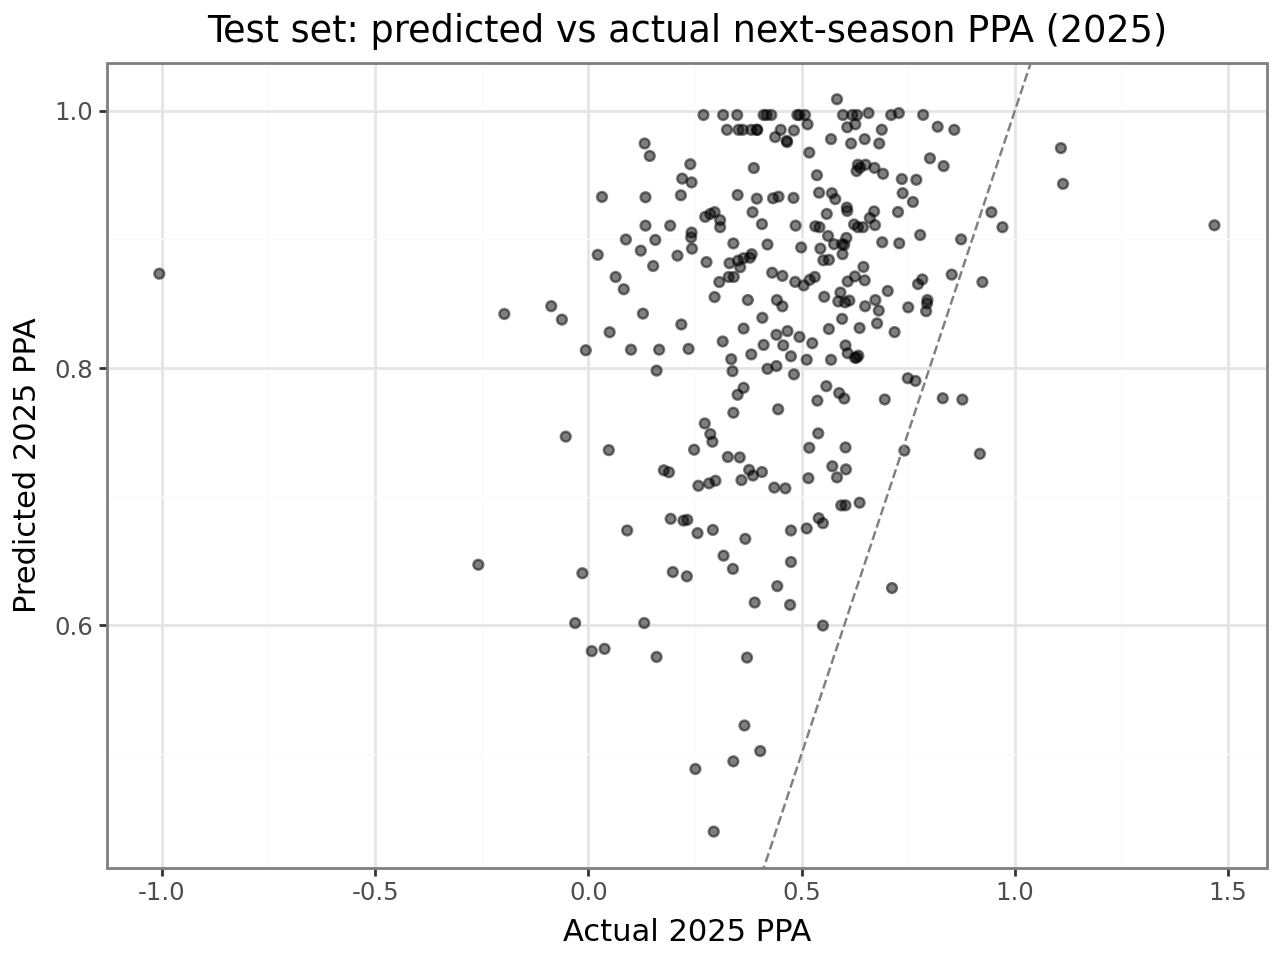

In [22]:
pred_df = pd.DataFrame({"actual": y_test.values, "predicted": test_pred})
(
    ggplot(pred_df, aes(x="actual", y="predicted"))
    + geom_point(alpha=0.5)
    + geom_abline(intercept=0, slope=1, linetype="dashed", color="grey")
    + theme_bw()
    + labs(title="Test set: predicted vs actual next-season PPA (2025)",
           x="Actual 2025 PPA", y="Predicted 2025 PPA")
)

## Variable importance

In [23]:
imp_gain = xgb_tuned.get_score(importance_type='gain')
imp_weight = xgb_tuned.get_score(importance_type='weight')
imp_cover = xgb_tuned.get_score(importance_type='cover')
imp_total_gain = xgb_tuned.get_score(importance_type='total_gain')

def to_df(d, kind):
    if not d:
        return pd.DataFrame(columns=['feature', 'kind', 'value'])
    return pd.Series(d).rename_axis('feature').reset_index(name='value').assign(kind=kind)

imp_long = pd.concat([to_df(imp_gain, 'gain'), to_df(imp_weight, 'weight'),
                      to_df(imp_cover, 'cover'), to_df(imp_total_gain, 'total_gain')], ignore_index=True)
imp_wide = imp_long.pivot_table(index='feature', columns='kind', values='value', aggfunc='first').reset_index()
imp_wide.sort_values('total_gain', ascending=False).head(20)

kind,feature,cover,gain,total_gain,weight
27,usg_rush,618.705872,2.079150,35.345554,17.0
0,avg_PPA_all,841.222229,3.897744,35.079693,9.0
3,avg_PPA_passing_downs,610.666687,2.182956,13.097733,6.0
17,rushing_long,615.000000,1.680761,11.765326,7.0
16,rushing_car,661.714294,1.364375,9.550626,7.0
2,avg_PPA_pass,769.400024,1.835904,9.179518,5.0
6,avg_PPA_standard_downs,913.000000,7.456221,7.456221,1.0
14,receiving_yds,875.000000,1.237856,7.427138,6.0
23,total_PPA_standard_downs,839.000000,1.726265,6.905060,4.0
18,rushing_td,325.333344,2.196818,6.590454,3.0


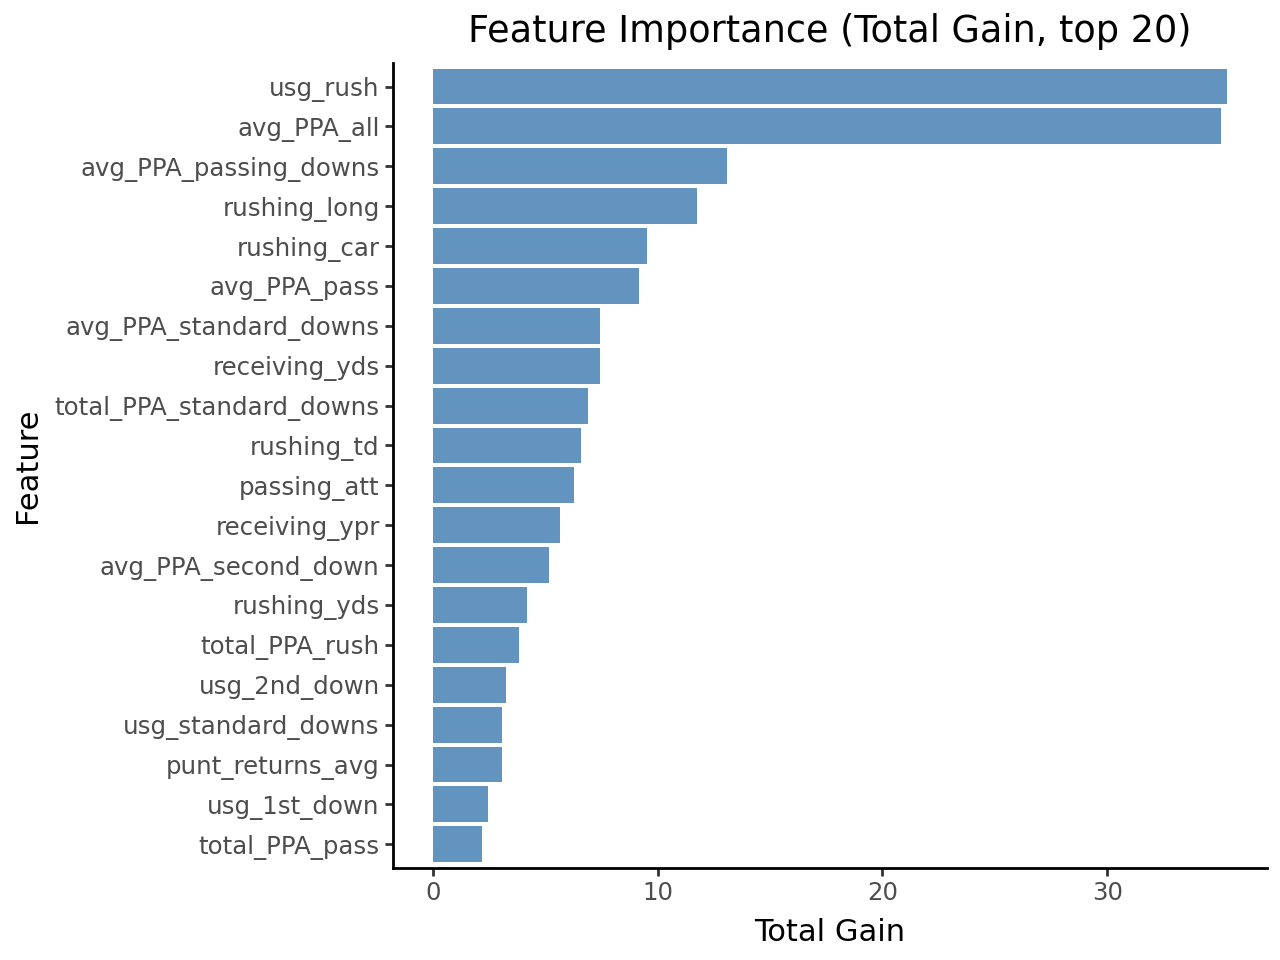

In [24]:
top_feats = imp_wide.sort_values('total_gain', ascending=False)['feature'].head(20).tolist()
plot_long = imp_long[imp_long['feature'].isin(top_feats)].copy()
order = imp_wide.set_index('feature').loc[top_feats, 'total_gain'].sort_values().index.tolist()
plot_long['feature'] = pd.Categorical(plot_long['feature'], categories=order, ordered=True)

(
    ggplot(plot_long[plot_long['kind'] == 'total_gain'], aes(y="value", x="feature"))
    + geom_col(fill="steelblue", alpha=0.85)
    + coord_flip()
    + theme_classic()
    + labs(title="Feature Importance (Total Gain, top 20)", x="Feature", y="Total Gain")
)

## Permutation importance (on the test set)

Scored on negative RMSE: a feature that matters will *increase* RMSE when shuffled.

In [25]:
class BoosterWrapper:
    def __init__(self, booster): self.booster = booster
    def fit(self, X, y=None): return self

def rmse_scorer(model, X, y):
    return -rmse(y, model.booster.predict(xgb.DMatrix(X)))

perm = permutation_importance(BoosterWrapper(xgb_tuned), X_test, np.asarray(y_test),
                              scoring=rmse_scorer, n_repeats=10, random_state=111111)
perm_df = pd.DataFrame({"feature": X_test.columns, "rmse_increase": -perm.importances_mean,
                        "sd": perm.importances_std}).sort_values("rmse_increase", ascending=False)
perm_df.head(20)

,feature,rmse_increase,sd
6,avg_PPA_standard_downs,0.000939,0.000382
14,total_PPA_standard_downs,0.000732,0.000755
10,total_PPA_rush,0.000724,0.000519
3,avg_PPA_first_down,0.000462,0.000173
29,receiving_yds,0.000411,0.000826
31,receiving_ypr,0.000397,0.000458
28,receiving_rec,0.000375,0.000267
67,punt_returns_avg,0.000285,0.000258
71,usg_pass,0.000232,0.000233
79,portal_rating,0.000099,0.000146


## SHAP values

In [26]:
explainer = shap.TreeExplainer(xgb_tuned)
shap_values = explainer(X_train_full)

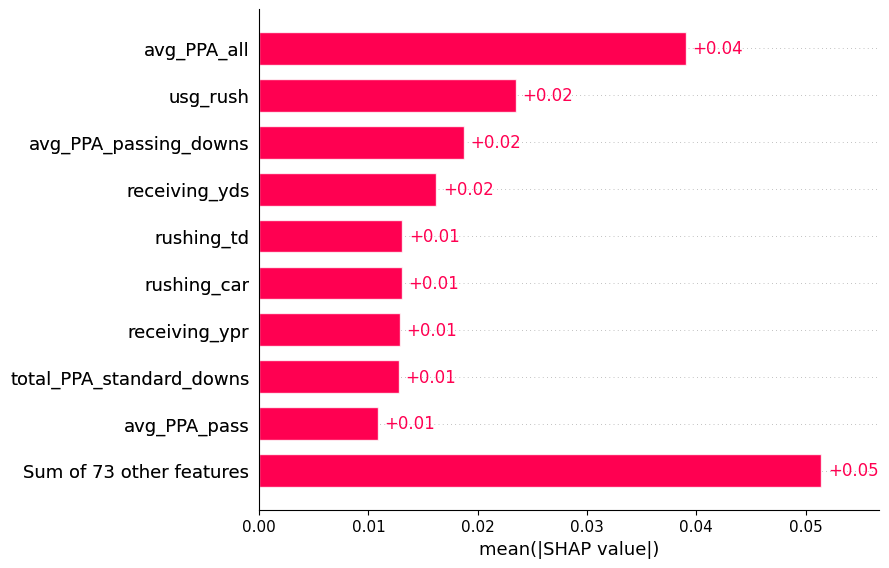

In [27]:
shap.plots.bar(shap_values, max_display=10)

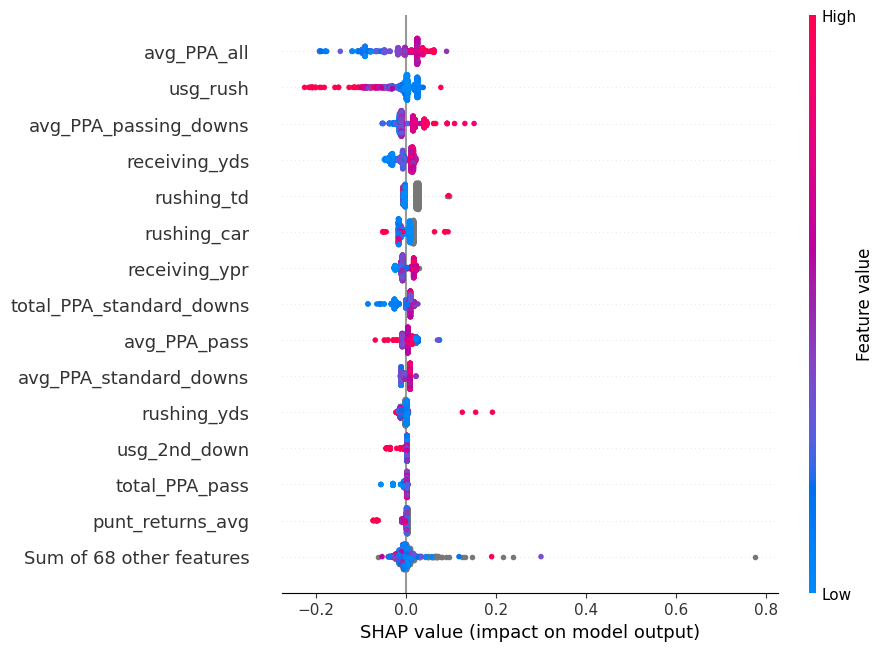

In [28]:
shap.initjs()
shap.plots.beeswarm(shap_values, max_display=15)

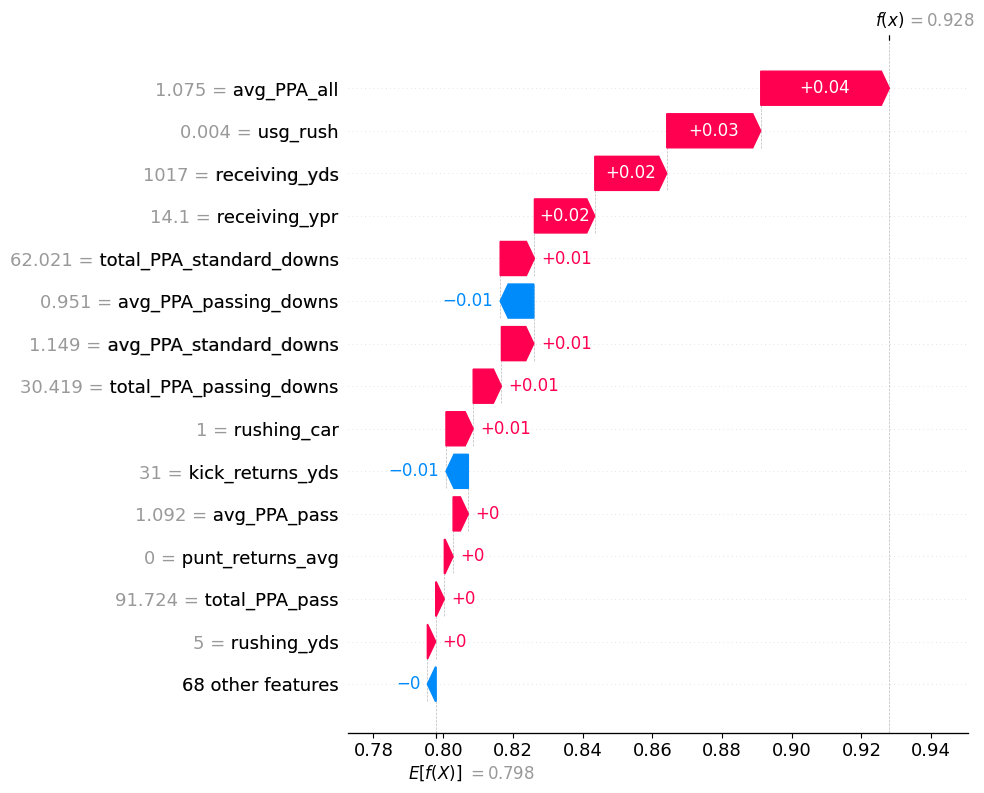

In [29]:
row_idx = 0
shap.plots.waterfall(shap_values[row_idx], max_display=15)

## Forecast next season (2026 PPA) for 2025 players


In [30]:
latest = test_clean[(test_clean[SEASON_COL] == test_season) & (test_clean[USAGE_COL] >= MIN_USAGE_CURRENT)].copy()
X_latest, _ = make_xy(latest.assign(next_ppa=np.nan))
latest[f"pred_ppa_{test_season + 1}"] = xgb_tuned.predict(xgb.DMatrix(X_latest))

forecast = (latest[["name", "team", POS_COL, USAGE_COL, PPA_COL, f"pred_ppa_{test_season + 1}"]]
            .rename(columns={PPA_COL: f"ppa_{test_season}", POS_COL: "position"})
            .sort_values(f"pred_ppa_{test_season + 1}", ascending=False)
            .reset_index(drop=True))
forecast.to_csv(f"forecast_ppa_{test_season + 1}.csv", index=False)
print(len(forecast), "players forecast")
forecast.head(25)

972 players forecast


,name,team,position,usg_overall,ppa_2025,pred_ppa_2026
0,Adam Criter,San Diego,WR,0.250,0.072,1.451448
1,Noah Short,Army,WR,0.171,0.220,1.097731
2,Ryan Tattersall,Harvard,WR,0.062,0.861,1.073467
3,Noah Grevious,VMI,WR,0.122,0.626,1.052057
4,Omar Cooper Jr.,Indiana,WR,0.088,0.794,0.998178
5,Charlie Becker,Indiana,WR,0.053,1.254,0.996779
6,Cincere Gill,Presbyterian,WR,0.072,1.468,0.996779
7,Chris Barnes,Wake Forest,WR,0.093,0.349,0.984689
8,Landon Ellis,James Madison,WR,0.056,1.126,0.958511
9,Ben Ford,Boise State,WR,0.063,1.169,0.955553
